# AI Applications & Mini Project 4 — Workflow automation and reporting

**Digital Foundation for Chemical Engineers**  \nDuration: 60 minutes

## Today’s goal
Turn a production CSV into a repeatable shift summary and understand how automation can reduce routine effort while preserving review and accountability.

## 1. Where automation helps (10 min)

Workflow automation can import scheduled data, check completeness, calculate KPIs, prepare exception lists, draft reports, and route work for review. AI can help summarise text or prioritise cases, but routine calculations should remain transparent and testable.

A good automated report makes its source, time period, assumptions, and exceptions visible.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import urllib.request

# Create the data directory if it doesn't exist
os.makedirs('data', exist_ok=True)

# Download the missing dataset from GitHub
url = 'https://raw.githubusercontent.com/Khushi-chan/Module_5_6_Both/refs/heads/main/data/production_shift_120.csv'
try:
    urllib.request.urlretrieve(url, 'data/production_shift_120.csv')
    print("Successfully downloaded production_shift_120.csv")
except Exception as e:
    print(f"Could not download file: {e}")

link = 'https://raw.githubusercontent.com/Khushi-chan/Module_5_6_Both/refs/heads/main/05_04_workflow_automation_reporting.ipynb'

production = pd.read_csv('data/production_shift_120.csv')
production['timestamp'] = pd.to_datetime(production['timestamp'])
production.head()

Successfully downloaded production_shift_120.csv


,timestamp,line,throughput_kg_h,energy_kw,downtime_min,operator_note
0,2026-02-02 08:00:00,L1,940,170.0,0,Normal operation
1,2026-02-02 09:00:00,L2,949,173.5,0,Normal operation
2,2026-02-02 10:00:00,L1,958,177.0,0,Normal operation
3,2026-02-02 11:00:00,L2,967,180.5,0,Normal operation
4,2026-02-02 12:00:00,L1,976,184.0,0,Normal operation


## 2. Repeatable KPI calculation (12 min)
The code below acts as a small reporting pipeline: load data, calculate a summary, identify exceptions, then display results. This is automation—not a machine-learning model.

In [4]:
kpi_by_line = production.groupby('line').agg(
    average_throughput_kg_h=('throughput_kg_h', 'mean'),
    average_energy_kw=('energy_kw', 'mean'),
    total_downtime_min=('downtime_min', 'sum')
)
display(kpi_by_line.round(2))
print('Data period:', production['timestamp'].min(), 'to', production['timestamp'].max())

,average_throughput_kg_h,average_energy_kw,total_downtime_min
line,,,
L1,984.25,183.82,30
L2,985.00,183.65,0


Data period: 2026-02-02 08:00:00 to 2026-02-07 07:00:00


**Try it (4 min):** Which line has more downtime? Which KPI should a supervisor see first, and why?

**Challenge:** Calculate energy per unit throughput (energy_kw / throughput_kg_h) for each row and compare its average by line.

## 3. Exception list and trend (14 min)
An exception report lets a person focus on rows needing attention. Thresholds below are classroom examples.

,timestamp,line,throughput_kg_h,downtime_min,operator_note
0,2026-02-02 08:00:00,L1,940,0,Normal operation
1,2026-02-02 09:00:00,L2,949,0,Normal operation
11,2026-02-02 19:00:00,L2,940,0,Normal operation
12,2026-02-02 20:00:00,L1,949,0,Normal operation
22,2026-02-03 06:00:00,L1,940,0,Normal operation
23,2026-02-03 07:00:00,L2,949,0,Normal operation
33,2026-02-03 17:00:00,L2,940,0,Normal operation
34,2026-02-03 18:00:00,L1,949,0,Normal operation
44,2026-02-04 04:00:00,L1,940,15,Inspect pump
45,2026-02-04 05:00:00,L2,949,0,Normal operation


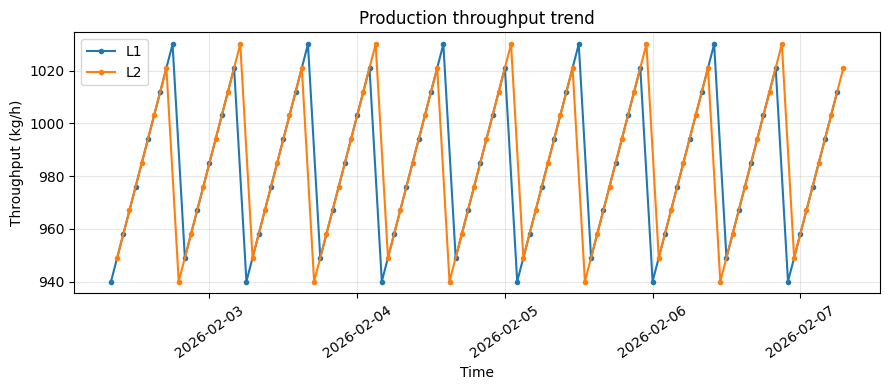

In [5]:
throughput_review_kg_h = 950
exceptions = production[(production['downtime_min'] > 0) |
                        (production['throughput_kg_h'] < throughput_review_kg_h)]
display(exceptions[['timestamp', 'line', 'throughput_kg_h', 'downtime_min', 'operator_note']])
plt.figure(figsize=(9, 4))
for line, group in production.groupby('line'):
    plt.plot(group['timestamp'], group['throughput_kg_h'], marker='.', label=line)
plt.title('Production throughput trend')
plt.xlabel('Time')
plt.ylabel('Throughput (kg/h)')
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 4. Automated reporting system design (11 min)
A real system needs more than a script: source permissions, data validation, versioned logic, scheduled execution, human review, error notifications, secure storage, and an audit trail. It should fail safely—if data are absent or abnormal, it must state that rather than produce a misleading report.

## Pair task (9 min)
Sketch a daily production-report workflow: input source → checks → calculations → charts/exceptions → reviewer → final audience. State one risk at each stage.

**Challenge:** Draft three concise bullets that could appear in a shift report using the calculated data.

## Exit check
You can distinguish automation from AI and design a transparent reporting workflow with a human reviewer. Next: AI assistants and project planning.